# 3. pandas, Polars and backtesting

Explore tables of study sessions: select rows, create columns, handle missing values and group results.
Compare pandas and Polars on the same data, then apply the operations to price histories.

In [1]:
from __future__ import annotations

from collections.abc import Callable
from functools import partial
from pathlib import Path
from statistics import median
from tempfile import TemporaryDirectory
from timeit import repeat

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

from quant_workshop.market import TRADING_DAYS, FloatArray, synthetic_prices

## pandas: create and inspect a table

A **DataFrame** is a table; a **Series** is one column. Each row here is a study session.
One session has no score yet. pandas represents that missing numerical value as NaN.

In [2]:
students: list[str] = ["Maya", "Leo", "Maya", "Asha", "Leo", "Asha"]
minutes: list[int] = [30, 20, 45, 30, 20, 40]
scores: list[float | None] = [60.0, 80.0, None, 70.0, 90.0, 85.0]
study_pd: pd.DataFrame = pd.DataFrame({"student": students, "minutes": minutes, "score": scores})
print(study_pd.head().to_string())
print("Rows and columns:", study_pd.shape)
print("Column types:\n", study_pd.dtypes)
print("One column:\n", study_pd["minutes"].to_string())

  student  minutes  score
0    Maya       30   60.0
1     Leo       20   80.0
2    Maya       45    NaN
3    Asha       30   70.0
4     Leo       20   90.0
Rows and columns: (6, 3)
Column types:
 student        str
minutes      int64
score      float64
dtype: object
One column:
 0    30
1    20
2    45
3    30
4    20
5    40


### Selecting, filtering and sorting

`.loc` selects row and column labels; `.iloc` selects positions. A Boolean mask selects rows.
Use `&` to combine pandas conditions, with parentheses around each condition.

In [3]:
print("First two rows:\n", study_pd.iloc[:2].to_string())
print("Two columns:\n", study_pd.loc[:, ["student", "score"]].to_string())
print("Maya's sessions:\n", study_pd.loc[study_pd["student"] == "Maya"].to_string())
print(
    "Long sessions scoring at least 70:\n",
    study_pd.loc[(study_pd["minutes"] >= 30) & (study_pd["score"] >= 70.0)].to_string(),
)
print("Longest first:\n", study_pd.sort_values("minutes", ascending=False).to_string())

First two rows:
   student  minutes  score
0    Maya       30   60.0
1     Leo       20   80.0
Two columns:
   student  score
0    Maya   60.0
1     Leo   80.0
2    Maya    NaN
3    Asha   70.0
4     Leo   90.0
5    Asha   85.0
Maya's sessions:
   student  minutes  score
0    Maya       30   60.0
2    Maya       45    NaN
Long sessions scoring at least 70:
   student  minutes  score
3    Asha       30   70.0
5    Asha       40   85.0
Longest first:
   student  minutes  score
2    Maya       45    NaN
5    Asha       40   85.0
0    Maya       30   60.0
3    Asha       30   70.0
1     Leo       20   80.0
4     Leo       20   90.0


### New columns and missing values

`.assign` returns a table with additional columns. Arithmetic works on whole columns, as in NumPy.
`.isna` identifies missing values; `.dropna` removes rows with missing values in chosen columns.
`.fillna` replaces them. Filling a score with zero changes its meaning to zero points;
leaving it missing excludes it from a mean. The calls below leave the original table unchanged.

In [4]:
print(study_pd.assign(hours=study_pd["minutes"] / 60.0).round(2).to_string())
print("Missing values per column:\n", study_pd.isna().sum())
print("Scored sessions:\n", study_pd.dropna(subset=["score"]).to_string())
print("If unscored sessions count as zero:\n", study_pd.fillna({"score": 0.0}).to_string())
assert study_pd["score"].isna().sum() == 1

  student  minutes  score  hours
0    Maya       30   60.0   0.50
1     Leo       20   80.0   0.33
2    Maya       45    NaN   0.75
3    Asha       30   70.0   0.50
4     Leo       20   90.0   0.33
5    Asha       40   85.0   0.67
Missing values per column:
 student    0
minutes    0
score      1
dtype: int64
Scored sessions:
   student  minutes  score
0    Maya       30   60.0
1     Leo       20   80.0
3    Asha       30   70.0
4     Leo       20   90.0
5    Asha       40   85.0
If unscored sessions count as zero:
   student  minutes  score
0    Maya       30   60.0
1     Leo       20   80.0
2    Maya       45    0.0
3    Asha       30   70.0
4     Leo       20   90.0
5    Asha       40   85.0


### Grouping and aggregation

Grouping collects rows with the same key. An aggregation produces a summary for each group.
The named outputs below sum minutes and average the available scores for each student.

In [5]:
summary_pd: pd.DataFrame = study_pd.groupby("student").agg(
    total_minutes=("minutes", "sum"), mean_score=("score", "mean")
)
print(summary_pd.sort_values("total_minutes", ascending=False).to_string())
assert summary_pd.loc["Maya", "total_minutes"] == 75
assert summary_pd.loc["Maya", "mean_score"] == 60.0

         total_minutes  mean_score
student                           
Maya                75        60.0
Asha                70        77.5
Leo                 40        85.0


## Polars: the same table operations

Polars has no separate row index: names and dates remain ordinary columns.
`pl.col("minutes")` is an **expression** describing work on a column.
`select` chooses columns, `filter` chooses rows, and `with_columns` adds or replaces columns.

In [6]:
study_pl: pl.DataFrame = pl.DataFrame({"student": students, "minutes": minutes, "score": scores})
print("Schema:", study_pl.schema)
print(study_pl.select("student", "score"))
print(study_pl.filter((pl.col("minutes") >= 30) & (pl.col("score") >= 70.0)))
print(study_pl.with_columns((pl.col("minutes") / 60.0).alias("hours")))
print(study_pl.sort("minutes", descending=True))

Schema: Schema({'student': String, 'minutes': Int64, 'score': Float64})
shape: (6, 2)
┌─────────┬───────┐
│ student ┆ score │
│ ---     ┆ ---   │
│ str     ┆ f64   │
╞═════════╪═══════╡
│ Maya    ┆ 60.0  │
│ Leo     ┆ 80.0  │
│ Maya    ┆ null  │
│ Asha    ┆ 70.0  │
│ Leo     ┆ 90.0  │
│ Asha    ┆ 85.0  │
└─────────┴───────┘
shape: (2, 3)
┌─────────┬─────────┬───────┐
│ student ┆ minutes ┆ score │
│ ---     ┆ ---     ┆ ---   │
│ str     ┆ i64     ┆ f64   │
╞═════════╪═════════╪═══════╡
│ Asha    ┆ 30      ┆ 70.0  │
│ Asha    ┆ 40      ┆ 85.0  │
└─────────┴─────────┴───────┘
shape: (6, 4)
┌─────────┬─────────┬───────┬──────────┐
│ student ┆ minutes ┆ score ┆ hours    │
│ ---     ┆ ---     ┆ ---   ┆ ---      │
│ str     ┆ i64     ┆ f64   ┆ f64      │
╞═════════╪═════════╪═══════╪══════════╡
│ Maya    ┆ 30      ┆ 60.0  ┆ 0.5      │
│ Leo     ┆ 20      ┆ 80.0  ┆ 0.333333 │
│ Maya    ┆ 45      ┆ null  ┆ 0.75     │
│ Asha    ┆ 30      ┆ 70.0  ┆ 0.5      │
│ Leo     ┆ 20      ┆ 90.0  ┆ 0.33333

Polars uses **null** for a missing value. Its numerical columns can also contain floating-point
NaN, which is a different value; `fill_null` does not replace NaN.
`alias` names an expression's output. A group mean ignores nulls, just as pandas ignores NaNs here.

In [7]:
print("Null counts:", study_pl.null_count())
print(study_pl.drop_nulls("score"))
print(study_pl.with_columns(pl.col("score").fill_null(0.0)))
summary_pl: pl.DataFrame = study_pl.group_by("student").agg(
    pl.col("minutes").sum().alias("total_minutes"),
    pl.col("score").mean().alias("mean_score"),
)
print(summary_pl.sort("total_minutes", descending=True))
np.testing.assert_allclose(
    summary_pd.sort_index().to_numpy(),
    summary_pl.sort("student").select("total_minutes", "mean_score").to_numpy(),
)

Null counts: shape: (1, 3)
┌─────────┬─────────┬───────┐
│ student ┆ minutes ┆ score │
│ ---     ┆ ---     ┆ ---   │
│ u32     ┆ u32     ┆ u32   │
╞═════════╪═════════╪═══════╡
│ 0       ┆ 0       ┆ 1     │
└─────────┴─────────┴───────┘
shape: (5, 3)
┌─────────┬─────────┬───────┐
│ student ┆ minutes ┆ score │
│ ---     ┆ ---     ┆ ---   │
│ str     ┆ i64     ┆ f64   │
╞═════════╪═════════╪═══════╡
│ Maya    ┆ 30      ┆ 60.0  │
│ Leo     ┆ 20      ┆ 80.0  │
│ Asha    ┆ 30      ┆ 70.0  │
│ Leo     ┆ 20      ┆ 90.0  │
│ Asha    ┆ 40      ┆ 85.0  │
└─────────┴─────────┴───────┘
shape: (6, 3)
┌─────────┬─────────┬───────┐
│ student ┆ minutes ┆ score │
│ ---     ┆ ---     ┆ ---   │
│ str     ┆ i64     ┆ f64   │
╞═════════╪═════════╪═══════╡
│ Maya    ┆ 30      ┆ 60.0  │
│ Leo     ┆ 20      ┆ 80.0  │
│ Maya    ┆ 45      ┆ 0.0   │
│ Asha    ┆ 30      ┆ 70.0  │
│ Leo     ┆ 20      ┆ 90.0  │
│ Asha    ┆ 40      ┆ 85.0  │
└─────────┴─────────┴───────┘
shape: (3, 3)
┌─────────┬───────────────┬────

| Task | pandas | Polars |
| --- | --- | --- |
| Choose columns | `frame[["student", "score"]]` | `frame.select("student", "score")` |
| Filter rows | `frame.loc[mask]` | `frame.filter(expression)` |
| Add columns | `frame.assign(...)` | `frame.with_columns(...)` |
| Group rows | `frame.groupby("student")` | `frame.group_by("student")` |
| Sort rows | `frame.sort_values("minutes")` | `frame.sort("minutes")` |
| Drop missing scores | `frame.dropna(subset=["score"])` | `frame.drop_nulls("score")` |

**Exercise:** in each library, select sessions with scores of at least 80, keeping only
the student and score columns. The next cell checks that both answers agree.

In [8]:
high_scores_pd: pd.DataFrame = study_pd.loc[study_pd["score"] >= 80.0, ["student", "score"]]
high_scores_pl: pl.DataFrame = study_pl.filter(pl.col("score") >= 80.0).select("student", "score")
print(high_scores_pd.to_string(index=False))
assert len(high_scores_pd) == high_scores_pl.height == 3
np.testing.assert_array_equal(
    high_scores_pd["score"].to_numpy(), high_scores_pl["score"].to_numpy()
)

student  score
    Leo   80.0
    Leo   90.0
   Asha   85.0


## Previous rows and moving averages

For a short history of website visits, `shift(1)` places the previous row beside the current row.
`rolling(3).mean()` averages the current and two previous values. The first rows are missing
because there is not enough history. `pct_change` calculates `current / previous - 1`.
`diff` subtracts the previous value, `abs` removes the sign, and `astype` changes a column's dtype.

In [9]:
visits: pd.Series[float] = pd.Series([100.0, 120.0, 90.0, 150.0, 180.0], name="visits")
history_pd: pd.DataFrame = visits.to_frame()
history_pd["previous"] = visits.shift(1)
history_pd["change"] = visits.pct_change(fill_method=None)
history_pd["three_day_mean"] = visits.rolling(3, min_periods=3).mean()
print(history_pd.round(3).to_string())
print("Differences:", visits.diff().tolist())
print("Absolute changes:", visits.diff().abs().tolist())
print("Visits above 120 as 0/1 flags:", (visits > 120.0).astype(float).tolist())

history_pl: pl.DataFrame = pl.DataFrame({"visits": visits.to_numpy()}).with_columns(
    pl.col("visits").shift(1).alias("previous"),
    (pl.col("visits") / pl.col("visits").shift(1) - 1.0).alias("change"),
    pl.col("visits").rolling_mean(window_size=3, min_samples=3).alias("three_day_mean"),
)
print(history_pl.select((pl.col("visits") > 120.0).cast(pl.Float64).alias("busy")))
np.testing.assert_allclose(history_pd.to_numpy(), history_pl.to_numpy(), equal_nan=True)

   visits  previous  change  three_day_mean
0   100.0       NaN     NaN             NaN
1   120.0     100.0   0.200             NaN
2    90.0     120.0  -0.250         103.333
3   150.0      90.0   0.667         120.000
4   180.0     150.0   0.200         140.000
Differences: [nan, 20.0, -30.0, 60.0, 30.0]
Absolute changes: [nan, 20.0, 30.0, 60.0, 30.0]
Visits above 120 as 0/1 flags: [0.0, 0.0, 0.0, 1.0, 1.0]
shape: (5, 1)
┌──────┐
│ busy │
│ ---  │
│ f64  │
╞══════╡
│ 0.0  │
│ 0.0  │
│ 0.0  │
│ 1.0  │
│ 1.0  │
└──────┘


## Optional: joins, files and lazy queries

A **join** attaches information from another table using a common key.
Here each student has one group. The validation checks that the lookup has one row per student,
so it cannot unexpectedly duplicate sessions.

In [10]:
roster_pd: pd.DataFrame = pd.DataFrame(
    {"student": ["Maya", "Leo", "Asha"], "group": ["A", "B", "A"]}
)
joined_pd: pd.DataFrame = study_pd.merge(
    roster_pd, on="student", how="left", validate="many_to_one"
)
joined_pl: pl.DataFrame = study_pl.join(
    pl.from_pandas(roster_pd), on="student", how="left", validate="m:1"
)
print(joined_pd.to_string(index=False))
assert len(joined_pd) == joined_pl.height == len(study_pd)

student  minutes  score group
   Maya       30   60.0     A
    Leo       20   80.0     B
   Maya       45    NaN     A
   Asha       30   70.0     A
    Leo       20   90.0     B
   Asha       40   85.0     A


Both libraries can read and write CSV files. This example uses a temporary directory,
which Python removes when the block ends.
A **lazy query** describes operations before executing them. `scan_csv` can push eligible
filters and column selection towards the file read; `collect()` runs the query.

In [11]:
with TemporaryDirectory() as directory:
    pandas_path: Path = Path(directory) / "pandas_sessions.csv"
    polars_path: Path = Path(directory) / "polars_sessions.csv"
    study_pd.to_csv(pandas_path, index=False)
    study_pl.write_csv(polars_path)
    print("pandas read:", pd.read_csv(pandas_path).shape)
    print("Polars read:", pl.read_csv(polars_path).shape)
    study_query: pl.LazyFrame = (
        pl.scan_csv(pandas_path).filter(pl.col("score") >= 80.0).select("student", "score")
    )
    print(study_query.explain())
    assert study_query.collect().height == 3

pandas read: (6, 3)
Polars read: (6, 3)
Csv SCAN [/var/folders/13/y91gmq717c3f2cd23lv79kkh0000gn/T/tmpy7rpfavl/pandas_sessions.csv]
PROJECT 2/3 COLUMNS
SELECTION: col("score") >= 80.0
ESTIMATED ROWS: 7


## Using tables for price histories

A **backtest** simulates trading decisions using historical observations.
The data below contains invented asset prices. A price return uses the same fractional-change
calculation as the visit counts above. A moving average and a delayed signal use the same
`rolling` and `shift` operations.

In [12]:
prices: pd.DataFrame = synthetic_prices()
print(prices.head().round(2).to_string())
print("\npandas column types:\n", prices.dtypes)
print("\nTwo assets on the first three dates:\n", prices.loc[:, ["ALPHA", "BETA"]].head(3))
assert prices.shape == (756, 3)
assert (prices.iloc[0] == 100.0).all()
assert np.isfinite(prices.to_numpy()).all() and (prices > 0.0).all().all()
pd.testing.assert_frame_equal(prices, synthetic_prices())

             ALPHA    BETA   GAMMA
date                              
2022-01-03  100.00  100.00  100.00
2022-01-04   99.69   99.76  100.16
2022-01-05   99.09   99.97   98.31
2022-01-06   98.10   98.64   99.13
2022-01-07   97.89   97.58   98.30

pandas column types:
 ALPHA    float64
BETA     float64
GAMMA    float64
dtype: object

Two assets on the first three dates:
                  ALPHA        BETA
date                              
2022-01-03  100.000000  100.000000
2022-01-04   99.690228   99.762403
2022-01-05   99.088756   99.967326


A pandas **DataFrame** is a table; a **Series** is one column. The index labels rows with dates.
`.loc` selects labels; `.iloc` selects positions. `.head()` previews a few rows.
The generator uses a fixed seed, correlated log returns, and weekday dates.
The dates include weekdays without accounting for exchange holidays. Assets are fictional.

Our fixed rule: if ALPHA's close exceeds its trailing 20-close average, aim to hold it;
otherwise hold cash. The average includes the current close and needs 20 observations.

Observe the signal at close t; trade at close t+1; first earn the
close-to-close return ending t+2. Thus held exposure is `signal.shift(2)`.
This full extra bar avoids assuming we can observe a close and also trade at that exact price.

In [13]:
window: int = 20
cost_bps: float = 5.0
fee_rate: float = cost_bps / 10_000.0


def backtest_pandas(close: pd.Series[float]) -> pd.DataFrame:
    frame = close.to_frame("price")
    frame["return"] = frame["price"].pct_change(fill_method=None).fillna(0.0)
    frame["mean_price"] = frame["price"].rolling(window, min_periods=window).mean()
    frame["signal"] = (frame["price"] > frame["mean_price"]).astype(float)
    frame["position"] = frame["signal"].shift(2, fill_value=0.0)
    frame["turnover"] = frame["position"].diff().abs().fillna(0.0)
    frame["gross"] = frame["position"] * frame["return"]
    frame["net"] = (1.0 - fee_rate * frame["turnover"]) * (1.0 + frame["gross"]) - 1.0
    frame["equity"] = (1.0 + frame["net"]).cumprod()
    return frame


backtest: pd.DataFrame = backtest_pandas(prices["ALPHA"])
print(backtest.iloc[16:26].round(5).to_string())

               price   return  mean_price  signal  position  turnover  gross  net  equity
date                                                                                     
2022-01-25  94.36725 -0.00840         NaN     0.0       0.0       0.0   -0.0  0.0     1.0
2022-01-26  93.61118 -0.00801         NaN     0.0       0.0       0.0   -0.0  0.0     1.0
2022-01-27  93.59062 -0.00022         NaN     0.0       0.0       0.0   -0.0  0.0     1.0
2022-01-28  93.16891 -0.00451    96.82075     0.0       0.0       0.0   -0.0  0.0     1.0
2022-01-31  92.25285 -0.00983    96.43339     0.0       0.0       0.0   -0.0  0.0     1.0
2022-02-01  92.64094  0.00421    96.08093     0.0       0.0       0.0    0.0  0.0     1.0
2022-02-02  92.51672 -0.00134    95.75232     0.0       0.0       0.0   -0.0  0.0     1.0
2022-02-03  91.45300 -0.01150    95.41999     0.0       0.0       0.0   -0.0  0.0     1.0
2022-02-04  89.81840 -0.01787    95.01636     0.0       0.0       0.0   -0.0  0.0     1.0
2022-02-07

Missing values are expected during the rolling window's warm-up. Comparisons against those
missing averages produce no entry signal. The first return is set to zero only for accounting:
we have no previous observation. A position of 1 means fully invested; 0 means cash.

One **basis point** is 0.01%, so 5 bps = 0.05% = 0.0005. Turnover of 1 costs one fee;
entering and later exiting costs two. The fee reduces wealth at the start of the return period,
then that period's gross return applies. We do not charge a forced sale at the final date.
Cash earns zero; dividends, taxes, market impact, and fill uncertainty are omitted.

The first 504 price rows are the development period. We report the final 252 rows separately.
The rule and cost are fixed before looking at that period; do not tune them on its result.

In [14]:
split: int = 504
holdout: pd.DataFrame = backtest.iloc[split:]


def summarise(values: pd.Series[float]) -> dict[str, float]:
    returns_array: FloatArray = values.to_numpy(dtype=np.float64)
    equity: FloatArray = np.concatenate([np.array([1.0]), np.cumprod(1.0 + returns_array)])
    drawdown: FloatArray = equity / np.maximum.accumulate(equity) - 1.0
    return {
        "Total return": float(equity[-1] - 1.0),
        "Annualised volatility": float(returns_array.std(ddof=1) * np.sqrt(TRADING_DAYS)),
        "Maximum drawdown": float(-drawdown.min()),
    }


summary: pd.DataFrame = pd.DataFrame(
    {
        "Before costs": summarise(holdout["gross"]),
        "After costs": summarise(holdout["net"]),
    }
)
print("Evaluation period only (fractions):\n", summary.round(4).to_string())
print("Position changes over the full sample:", int(backtest["turnover"].sum()))

Evaluation period only (fractions):
                        Before costs  After costs
Total return                 0.2240       0.2131
Annualised volatility        0.1180       0.1179
Maximum drawdown             0.0649       0.0686
Position changes over the full sample: 87


**Maximum drawdown** is the largest fall from a previous equity peak; the table reports its
positive magnitude. We include initial wealth of 1 so a loss on the first day is counted.
Annualising daily volatility by √252 assumes a stable process with uncorrelated daily returns.
The synthetic returns contain no deliberate trend signal.

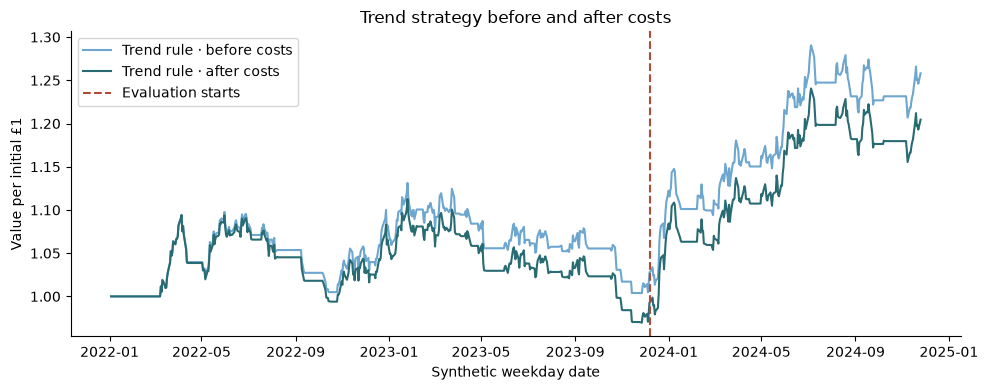

In [15]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    backtest.index,
    (1.0 + backtest["gross"]).cumprod(),
    label="Trend rule · before costs",
    alpha=0.65,
)
ax.plot(backtest.index, backtest["equity"], label="Trend rule · after costs", color="#286b73")
ax.axvline(backtest.index[split], color="#b34a36", linestyle="--", label="Evaluation starts")
ax.set(
    xlabel="Synthetic weekday date",
    ylabel="Value per initial £1",
    title="Trend strategy before and after costs",
)
ax.legend()
plt.tight_layout()
plt.show()

## Optional: the backtest in Polars

`pl.col("price")` is an **expression** describing work on a column.
`with_columns` adds or replaces columns; `alias` names a result.
Each stage below uses columns produced by earlier stages. Their order is part of the calculation.

In [16]:
polars_prices: pl.DataFrame = pl.from_pandas(
    prices[["ALPHA"]].rename(columns={"ALPHA": "price"}).reset_index()
)
polars_backtest: pl.DataFrame = (
    polars_prices.with_columns(
        (pl.col("price") / pl.col("price").shift(1) - 1.0).fill_null(0.0).alias("return"),
        pl.col("price").rolling_mean(window_size=window, min_samples=window).alias("mean_price"),
    )
    .with_columns(
        (pl.col("price") > pl.col("mean_price")).fill_null(False).cast(pl.Float64).alias("signal")
    )
    .with_columns(pl.col("signal").shift(2).fill_null(0.0).alias("position"))
    .with_columns(
        (pl.col("position") - pl.col("position").shift(1).fill_null(0.0)).abs().alias("turnover")
    )
    .with_columns((pl.col("position") * pl.col("return")).alias("gross"))
    .with_columns(
        ((1.0 - fee_rate * pl.col("turnover")) * (1.0 + pl.col("gross")) - 1.0).alias("net")
    )
    .with_columns((1.0 + pl.col("net")).cum_prod().alias("equity"))
)
print(polars_backtest.slice(16, 10))

for column in backtest.columns:
    np.testing.assert_allclose(
        backtest[column].to_numpy(),
        polars_backtest[column].to_numpy(),
        rtol=1e-11,
        atol=1e-14,
        equal_nan=True,
    )
print("pandas and Polars agree on every numerical column.")

shape: (10, 10)
┌─────────────────────┬───────────┬───────────┬────────────┬───┬──────────┬───────┬─────┬────────┐
│ date                ┆ price     ┆ return    ┆ mean_price ┆ … ┆ turnover ┆ gross ┆ net ┆ equity │
│ ---                 ┆ ---       ┆ ---       ┆ ---        ┆   ┆ ---      ┆ ---   ┆ --- ┆ ---    │
│ datetime[μs]        ┆ f64       ┆ f64       ┆ f64        ┆   ┆ f64      ┆ f64   ┆ f64 ┆ f64    │
╞═════════════════════╪═══════════╪═══════════╪════════════╪═══╪══════════╪═══════╪═════╪════════╡
│ 2022-01-25 00:00:00 ┆ 94.367248 ┆ -0.008396 ┆ null       ┆ … ┆ 0.0      ┆ -0.0  ┆ 0.0 ┆ 1.0    │
│ 2022-01-26 00:00:00 ┆ 93.611183 ┆ -0.008012 ┆ null       ┆ … ┆ 0.0      ┆ -0.0  ┆ 0.0 ┆ 1.0    │
│ 2022-01-27 00:00:00 ┆ 93.590622 ┆ -0.00022  ┆ null       ┆ … ┆ 0.0      ┆ -0.0  ┆ 0.0 ┆ 1.0    │
│ 2022-01-28 00:00:00 ┆ 93.168912 ┆ -0.004506 ┆ 96.820748  ┆ … ┆ 0.0      ┆ -0.0  ┆ 0.0 ┆ 1.0    │
│ 2022-01-31 00:00:00 ┆ 92.252849 ┆ -0.009832 ┆ 96.43339   ┆ … ┆ 0.0      ┆ -0.0  ┆ 0.0 ┆ 1.0

pandas uses typed column arrays and compiled operations. Polars is implemented in Rust,
uses columnar memory, and can parallelise supported operations. Calling a Python function
for each row or value with `apply` or `map_elements` adds Python overhead.

Compare mean return by asset across 300,000 synthetic observations.
Data generation and conversion are excluded from the timings.
Results depend on row count, dtypes and hardware.

In [17]:
rng = np.random.default_rng(9)
observations: int = 300_000
labels = rng.choice(["ALPHA", "BETA", "GAMMA"], observations)
observed_returns: FloatArray = rng.normal(0.0002, 0.01, observations)
records: list[tuple[str, float]] = list(
    zip(labels.tolist(), observed_returns.tolist(), strict=True)
)
pandas_observations: pd.DataFrame = pd.DataFrame({"asset": labels, "return": observed_returns})
polars_observations: pl.DataFrame = pl.from_pandas(pandas_observations)


def mean_by_asset_python(rows: list[tuple[str, float]]) -> dict[str, float]:
    totals: dict[str, float] = {}
    counts: dict[str, int] = {}
    for asset, value in rows:
        totals[asset] = totals.get(asset, 0.0) + value
        counts[asset] = counts.get(asset, 0) + 1
    return {asset: total / counts[asset] for asset, total in totals.items()}


def mean_by_asset_pandas(frame: pd.DataFrame) -> pd.Series[float]:
    return frame.groupby("asset")["return"].mean().sort_index()


def mean_by_asset_polars(frame: pl.DataFrame) -> pl.DataFrame:
    return frame.group_by("asset").agg(pl.col("return").mean()).sort("asset")


reference: dict[str, float] = mean_by_asset_python(records)
ordered: list[float] = [reference[asset] for asset in sorted(reference)]
np.testing.assert_allclose(
    mean_by_asset_pandas(pandas_observations).to_numpy(), ordered, atol=1e-14
)
np.testing.assert_allclose(
    mean_by_asset_polars(polars_observations)["return"].to_numpy(), ordered, atol=1e-14
)

operations: list[tuple[str, Callable[[], object]]] = [
    ("Python", partial(mean_by_asset_python, records)),
    ("pandas", partial(mean_by_asset_pandas, pandas_observations)),
    ("Polars", partial(mean_by_asset_polars, polars_observations)),
]
for label, operation in operations:
    operation()
    milliseconds: float = median(repeat(operation, number=3, repeat=5)) / 3.0 * 1_000.0
    print(f"{label:>6}: {milliseconds:.3f} ms per grouped calculation")

Python: 18.937 ms per grouped calculation
pandas: 3.350 ms per grouped calculation
Polars: 1.033 ms per grouped calculation


A Polars **lazy query** describes several operations before executing them.
The optimiser can remove unused columns and push eligible filters towards the data source.
With a file scan this can avoid reading irrelevant data. Calling `collect()` runs the plan.
Here the table is already in memory; `explain()` shows which columns the query needs.

In [18]:
query: pl.LazyFrame = (
    polars_backtest.lazy().filter(pl.col("position") == 1.0).select("date", "price", "net")
)
print(query.explain())
print(query.collect().head())

simple π 3/3 ["date", "price", "net"]
  FILTER col("position") == 1.0
  FROM
    DF ["date", "price", "return", "mean_price", ...]; PROJECT["date", "price", "net", "position"] 4/10 COLUMNS
shape: (5, 3)
┌─────────────────────┬───────────┬───────────┐
│ date                ┆ price     ┆ net       │
│ ---                 ┆ ---       ┆ ---       │
│ datetime[μs]        ┆ f64       ┆ f64       │
╞═════════════════════╪═══════════╪═══════════╡
│ 2022-03-09 00:00:00 ┆ 89.550856 ┆ 0.011501  │
│ 2022-03-10 00:00:00 ┆ 89.014146 ┆ -0.005993 │
│ 2022-03-11 00:00:00 ┆ 90.195532 ┆ 0.013272  │
│ 2022-03-14 00:00:00 ┆ 89.702304 ┆ -0.005468 │
│ 2022-03-15 00:00:00 ┆ 89.388502 ┆ -0.003498 │
└─────────────────────┴───────────┴───────────┘


**Exercise:** why would using `signal` without a shift introduce look-ahead bias?
Which return would the signal already know?
Before changing the window, predict whether more frequent trading increases the fee drag.
Try changes only on the development period; repeatedly inspecting the holdout makes it development data.

The check below changes future prices and verifies that earlier decisions and returns stay unchanged.
It also checks the execution delay directly.

In [19]:
changed_prices: pd.Series[float] = prices["ALPHA"].copy()
changed_prices.iloc[-10:] *= 4.0
changed_backtest: pd.DataFrame = backtest_pandas(changed_prices)
pd.testing.assert_frame_equal(backtest.iloc[:-10], changed_backtest.iloc[:-10])
np.testing.assert_array_equal(backtest["position"].iloc[2:], backtest["signal"].iloc[:-2])
assert (backtest["net"] <= backtest["gross"] + 1e-14).all()
print("Earlier rows are unaffected by later prices; positions follow the stated delay.")

Earlier rows are unaffected by later prices; positions follow the stated delay.


Further reading: [pandas tutorials](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html),
[pandas performance](https://pandas.pydata.org/docs/user_guide/enhancingperf.html),
[Polars lazy queries](https://docs.pola.rs/user-guide/concepts/lazy-api/).